# Face Quality Assessment (FQA) — face size, sharpness, brightness

**Purpose:** assess the quality of an already-cropped face image.
**Input:** a cropped face image.
**Output:** `quality_score`, `is_acceptable`, and one true/false flag each for `face_size`, `sharpness`, `brightness`.
**Evaluation metrics:** precision, recall, F1-score.

## Two methods, compared on the same test set

| | **A. OpenCV + calibrated thresholds** (baseline) | **B. MobileNetV3-Small** (trained model) |
|---|---|---|
| How it works | Measures face size, Laplacian sharpness and mean brightness, then compares each with a threshold | Fine-tuned CNN with 3 sigmoid outputs, one per check |
| What is learned | Only the thresholds (by maximising F1) | All weights, from labeled images |
| Explainable | Yes, each flag has a measured number behind it | Partly: probabilities only |
| `quality_score` | Weakest of three soft sub-scores | Lowest of the three predicted probabilities |
| `is_acceptable` | All three checks pass | All three probabilities are at least 0.5 |

Both are trained or calibrated on the same **train** split, tuned or early-stopped on **val**, and scored once on **test**. Splits are made by base image, so no photo appears in two splits.

## Dataset

Clean LFW face crops, degraded in controlled ways (shrunk, blurred, darkened or over-exposed). Because we know what was applied, each image has a true label for each check.

**Limitation to state in your report:** the labels are *synthetic*. High scores show the methods work under controlled conditions, not that they match human judgment on real photos. Section 11 lets you evaluate both methods on real images you label by hand.

## 1. Setup and configuration

In [5]:
import os, sys, json, random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, roc_auc_score, f1_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ---- Starter thresholds for method A (re-calibrated from data in section 5) ----
STARTER_THRESHOLDS = {
    "min_face_px": 112,        # shorter side of the cropped image, in pixels
    "min_sharpness": 100.0,    # contrast-normalised Laplacian variance
    "min_brightness": 60.0,    # mean gray level (0-255) of the face centre
    "max_brightness": 200.0,
}

# ---- Synthetic ground-truth settings ----
GT_MIN_FACE_PX = 112     # crops with a shorter side below this are labelled "face too small"
P_BAD = 0.4              # probability that each attribute is degraded in a sample
VARIANTS = {"train": 6, "val": 2, "test": 2}   # degraded variants per clean base image
BASE_SIDE = 150          # size of the clean base crops
MAX_BASE = 4000          # cap on clean base images (keeps the notebook fast)
LFW_MIN_FACES = 10       # LFW people with at least this many photos

# Optional: folder of your own good-quality face crops to use instead of LFW.
BASE_FACES_DIR = None

# ---- Method B (MobileNetV3-Small) settings ----
CANVAS = 160             # fixed network input; crops are padded onto it, not resized
PRETRAINED = True        # ImageNet weights (needs internet). False = train from scratch
EPOCHS_HEAD = 4          # phase 1: train only the new output layer
EPOCHS_FINETUNE = 15     # phase 2: fine-tune the whole network (early stopping applies)
BATCH_SIZE = 64

## 2. Method A: measurements and decision logic

All three measurements are computed on the **centre 70%** of the crop so that background and hair at the edges matter less.

In [6]:
SHARP_REF_SIZE = 112
CENTER_FRAC = 0.7


def center_gray(img_bgr, frac=CENTER_FRAC):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    ch, cw = max(1, int(h * frac)), max(1, int(w * frac))
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    return gray[y0:y0 + ch, x0:x0 + cw]


def normalised_center(img_bgr):
    # Downscale (never upscale) to a reference size so large crops are not favoured,
    # then normalise contrast so dark or washed-out crops are not automatically "blurry".
    h, w = img_bgr.shape[:2]
    scale = min(1.0, SHARP_REF_SIZE / min(h, w))
    if scale < 1.0:
        img_bgr = cv2.resize(img_bgr, (max(8, round(w * scale)), max(8, round(h * scale))),
                             interpolation=cv2.INTER_AREA)
    g = center_gray(img_bgr).astype(np.float32)
    return (g - g.mean()) / max(g.std(), 10.0) * 50.0


def measure_face_quality(img_bgr):
    h, w = img_bgr.shape[:2]
    g = normalised_center(img_bgr)
    return {
        "face_px": int(min(h, w)),
        "sharpness": float(cv2.Laplacian(g, cv2.CV_32F).var()),
        "brightness": float(center_gray(img_bgr).mean()),
    }


def tenengrad(img_bgr):
    # A different sharpness measure (mean Sobel gradient). Used ONLY to pick clean base images,
    # so the evaluation is not circular (the tested metric does not decide what counts as "sharp").
    g = normalised_center(img_bgr)
    gx, gy = cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1)
    return float(np.sqrt(gx ** 2 + gy ** 2).mean())


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def read_image(img):
    if isinstance(img, np.ndarray):
        return img
    out = cv2.imread(str(img))
    if out is None:
        raise ValueError(f"Could not read image: {img}")
    return out


def assess_face_quality(img, thresholds=None):
    # Method A. Returns the outputs required by the spec, plus the raw measurements.
    T = thresholds or THRESHOLDS
    m = measure_face_quality(read_image(img))

    ok_size = m["face_px"] >= T["min_face_px"]
    ok_sharp = m["sharpness"] >= T["min_sharpness"]
    ok_bright = T["min_brightness"] <= m["brightness"] <= T["max_brightness"]

    # Soft sub-scores in [0, 1]; each equals 0.5 exactly at its threshold.
    s_size = sigmoid((m["face_px"] - T["min_face_px"] + 0.5) / (0.1 * T["min_face_px"]))
    s_sharp = sigmoid((np.log(max(m["sharpness"], 1e-6)) - np.log(T["min_sharpness"])) / 0.35)
    s_bright = min(sigmoid((m["brightness"] - T["min_brightness"]) / 12.0),
                   sigmoid((T["max_brightness"] - m["brightness"]) / 12.0))
    quality_score = float(min(s_size, s_sharp, s_bright))     # weakest link

    return {
        "quality_score": round(quality_score, 4),
        "is_acceptable": bool(ok_size and ok_sharp and ok_bright),
        "face_size": bool(ok_size),
        "sharpness": bool(ok_sharp),
        "brightness": bool(ok_bright),
        "metrics": {k: round(v, 3) for k, v in m.items()},
    }


THRESHOLDS = dict(STARTER_THRESHOLDS)   # replaced by calibrated values in section 5

## 3. Dataset: clean LFW crops + controlled degradations

1. Load LFW face crops (about 150×150, slightly padded around the face).
2. Keep only a **clean** subset: sharp according to an *independent* measure (Tenengrad), and with moderate brightness.
3. Split the clean images **by base image** into train (60%), val (20%) and test (20%).
4. For each clean image, randomly apply any combination of:
   - **too small**: downscale to 32–111 px (good: 112–150 px),
   - **blurry**: Gaussian or motion blur,
   - **bad brightness**: darkened to a mean of 15–60, or over-exposed to a mean of 205–250.
5. The label for each attribute is known from what was applied. `is_acceptable` = all three attributes are fine.

If the LFW download fails, put your own good face crops in a folder and set `BASE_FACES_DIR` in section 1.

In [7]:
from pathlib import Path


def load_base_faces():
    if BASE_FACES_DIR:
        faces = []
        for p in sorted(Path(BASE_FACES_DIR).rglob("*")):
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                im = cv2.imread(str(p))
                if im is None:
                    continue
                h, w = im.shape[:2]
                s = min(h, w)
                y0, x0 = (h - s) // 2, (w - s) // 2
                faces.append(cv2.resize(im[y0:y0 + s, x0:x0 + s], (BASE_SIDE, BASE_SIDE),
                                        interpolation=cv2.INTER_AREA))
        return faces

    from sklearn.datasets import fetch_lfw_people
    lfw = fetch_lfw_people(min_faces_per_person=LFW_MIN_FACES, color=True, resize=1.0, funneled=True,
                           slice_=(slice(55, 205), slice(55, 205)))
    imgs = lfw.images
    if imgs.max() <= 1.0:            # newer scikit-learn versions return floats in [0, 1]
        imgs = imgs * 255.0
    imgs = np.clip(imgs, 0, 255).astype(np.uint8)          # RGB
    return [cv2.cvtColor(im, cv2.COLOR_RGB2BGR) for im in imgs]


base_all = load_base_faces()
print("Loaded base faces:", len(base_all))

base_feats = pd.DataFrame([{**measure_face_quality(im), "tenengrad": tenengrad(im)} for im in base_all])
tenen_cut = base_feats["tenengrad"].quantile(0.40)
clean_mask = ((base_feats["tenengrad"] >= tenen_cut)
              & base_feats["brightness"].between(80, 190)
              & (base_feats["face_px"] >= GT_MIN_FACE_PX))

base_clean = [im for im, keep in zip(base_all, clean_mask) if keep]
order = rng.permutation(len(base_clean))[:MAX_BASE]
base_clean = [base_clean[i] for i in order]
del base_all
print("Clean base faces kept:", len(base_clean))

Loaded base faces: 4324
Clean base faces kept: 2562


In [8]:
def motion_blur(img, length, angle):
    k = np.zeros((length, length), np.float32)
    k[length // 2, :] = 1.0
    M = cv2.getRotationMatrix2D(((length - 1) / 2, (length - 1) / 2), angle, 1.0)
    k = cv2.warpAffine(k, M, (length, length))
    if k.sum() <= 0:
        return img
    return cv2.filter2D(img, -1, k / k.sum())


def degrade(img, bad_size, bad_sharp, bad_bright, rng):
    img = img.copy()

    # 1) face size
    side = int(rng.integers(32, GT_MIN_FACE_PX)) if bad_size else int(rng.integers(GT_MIN_FACE_PX, BASE_SIDE + 1))
    if side != img.shape[0]:
        img = cv2.resize(img, (side, side), interpolation=cv2.INTER_AREA)

    # 2) blur (applied after resizing so its strength is the same in pixels)
    if bad_sharp:
        if rng.random() < 0.5:
            img = cv2.GaussianBlur(img, (0, 0), float(rng.uniform(1.2, 3.5)))
        else:
            img = motion_blur(img, int(rng.integers(7, 21)), float(rng.uniform(0, 180)))

    # 3) brightness
    if bad_bright:
        base_mean = max(float(center_gray(img).mean()), 1.0)
        if rng.random() < 0.5:                               # too dark
            target = rng.uniform(15, 60)
            img = np.clip(img.astype(np.float32) * (target / base_mean), 0, 255).astype(np.uint8)
        else:                                                # over-exposed
            target = rng.uniform(205, 250)
            gain = max(1.0, target / base_mean)
            out = img
            for _ in range(40):
                out = np.clip(img.astype(np.float32) * gain, 0, 255).astype(np.uint8)
                if center_gray(out).mean() >= target:
                    break
                gain *= 1.1
            img = out
    return img


def build_split(base_images, rng, variants):
    rows, images = [], []
    for i, base in enumerate(base_images):
        for v in range(variants):
            bad_size, bad_sharp, bad_bright = (rng.random(3) < P_BAD)
            img = degrade(base, bad_size, bad_sharp, bad_bright, rng)
            rows.append({
                "base_id": i,
                **measure_face_quality(img),
                "y_size": not bad_size, "y_sharp": not bad_sharp, "y_bright": not bad_bright,
                "y_ok": not (bad_size or bad_sharp or bad_bright),
            })
            images.append(img)
    return pd.DataFrame(rows), images


idx = np.arange(len(base_clean))
train_idx, rest_idx = train_test_split(idx, test_size=0.4, random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, random_state=SEED)

train_df, train_imgs = build_split([base_clean[i] for i in train_idx], rng, VARIANTS["train"])
val_df,   val_imgs   = build_split([base_clean[i] for i in val_idx],   rng, VARIANTS["val"])
test_df,  test_imgs  = build_split([base_clean[i] for i in test_idx],  rng, VARIANTS["test"])

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)} samples")
print("\nShare of test samples where each attribute is GOOD:")
print(test_df[["y_size", "y_sharp", "y_bright", "y_ok"]].mean().round(3).to_string())

Train: 9222 | Val: 1024 | Test: 1026 samples

Share of test samples where each attribute is GOOD:
y_size      0.595
y_sharp     0.591
y_bright    0.612
y_ok        0.214


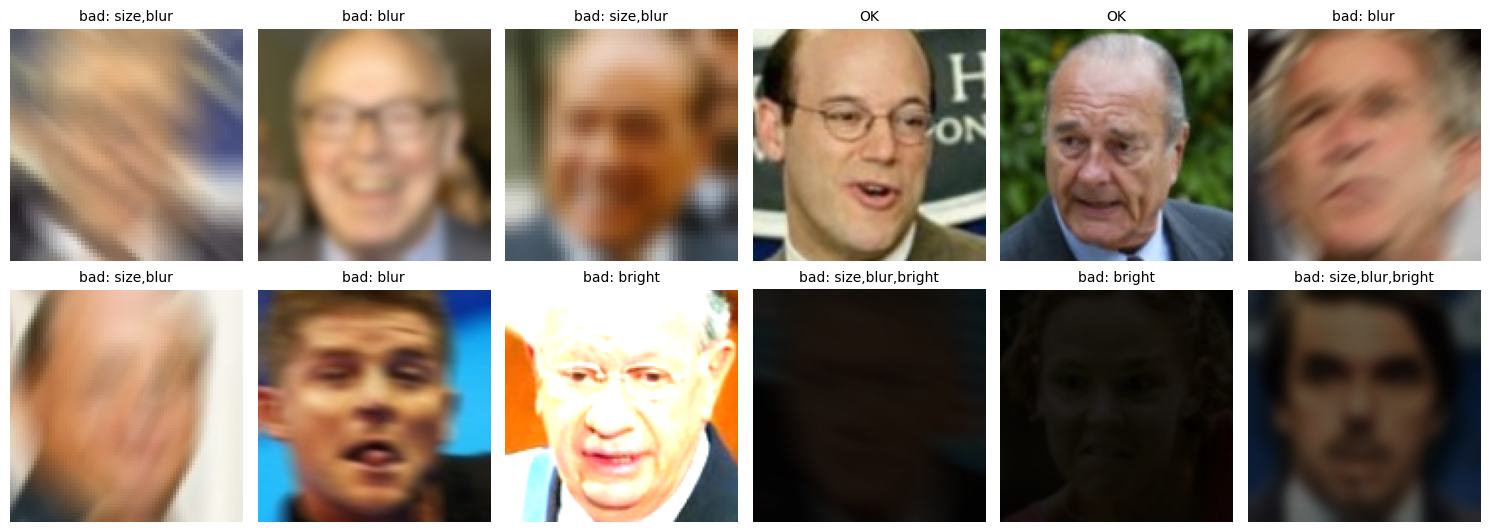

In [9]:
# Look at some generated samples
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, i in zip(axes.ravel(), rng.choice(len(test_df), 12, replace=False)):
    r = test_df.iloc[i]
    ax.imshow(cv2.cvtColor(test_imgs[i], cv2.COLOR_BGR2RGB))
    bad = [n for n, k in [("size", "y_size"), ("blur", "y_sharp"), ("bright", "y_bright")] if not r[k]]
    ax.set_title("OK" if not bad else "bad: " + ",".join(bad), fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Look at the measurements before choosing thresholds

If the "good" and "bad" distributions overlap a lot for an attribute, no threshold can do well, and you should say so in your report.

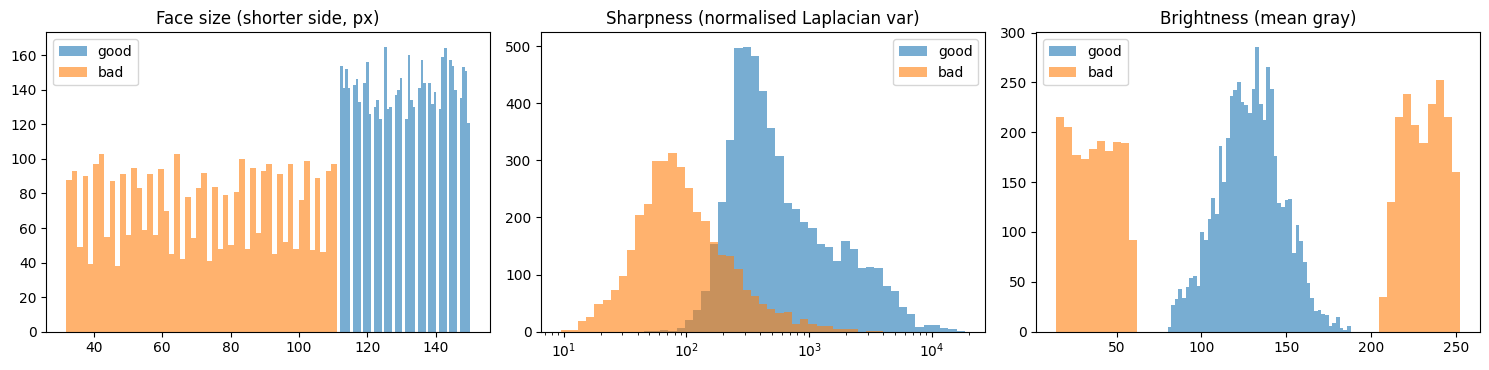

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, ycol, title, log) in zip(axes, [
        ("face_px", "y_size", "Face size (shorter side, px)", False),
        ("sharpness", "y_sharp", "Sharpness (normalised Laplacian var)", True),
        ("brightness", "y_bright", "Brightness (mean gray)", False)]):
    vals = train_df[col].clip(lower=1e-3)
    bins = np.logspace(np.log10(vals.min()), np.log10(vals.max()), 50) if log else 50
    ax.hist(vals[train_df[ycol]], bins=bins, alpha=0.6, label="good")
    ax.hist(vals[~train_df[ycol]], bins=bins, alpha=0.6, label="bad")
    if log: ax.set_xscale("log")
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

## 5. Method A: calibrate thresholds (maximise F1 on the train split)

Where many thresholds give the same best F1, the middle of that range is used, which is more stable than its edge.

In [11]:
def plateau_median(candidates, f1_values):
    f1_values = np.asarray(f1_values)
    best = f1_values.max()
    return float(np.median(np.asarray(candidates)[f1_values >= best - 1e-9])), float(best)


# Face size
cands = np.arange(32, 151)
t_size, f1_size = plateau_median(
    cands, [f1_score(train_df["y_size"], train_df["face_px"] >= t, zero_division=0) for t in cands])

# Sharpness
cands = np.unique(np.quantile(train_df["sharpness"], np.linspace(0.005, 0.995, 300)))
t_sharp, f1_sharp = plateau_median(
    cands, [f1_score(train_df["y_sharp"], train_df["sharpness"] >= t, zero_division=0) for t in cands])

# Brightness: search the lower and upper bound together
b, yb = train_df["brightness"].values, train_df["y_bright"].values
grid = [(lo, hi) for lo in range(10, 131, 5) for hi in range(130, 251, 5)]
f1s = [f1_score(yb, (b >= lo) & (b <= hi), zero_division=0) for lo, hi in grid]
best = max(f1s)
tied = [g for g, f in zip(grid, f1s) if f >= best - 1e-9]
t_lo, t_hi = float(np.median([g[0] for g in tied])), float(np.median([g[1] for g in tied]))

CALIBRATED_THRESHOLDS = {
    "min_face_px": round(t_size),
    "min_sharpness": round(t_sharp, 2),
    "min_brightness": t_lo,
    "max_brightness": t_hi,
}
THRESHOLDS = dict(CALIBRATED_THRESHOLDS)

print("Starter   :", STARTER_THRESHOLDS)
print("Calibrated:", CALIBRATED_THRESHOLDS)
print(f"Train F1 -> size {f1_size:.3f} | sharpness {f1_sharp:.3f} | brightness {best:.3f}")

Starter   : {'min_face_px': 112, 'min_sharpness': 100.0, 'min_brightness': 60.0, 'max_brightness': 200.0}
Calibrated: {'min_face_px': 112, 'min_sharpness': 157.12, 'min_brightness': 67.5, 'max_brightness': 197.5}
Train F1 -> size 1.000 | sharpness 0.913 | brightness 1.000


## 6. Method A: results on the test split

Precision, recall and F1 are reported for the **true** class (face size / sharpness / brightness is acceptable).
The overall row is `is_acceptable`. Precision there answers "of the images we accepted, how many were really fine?", which is the number that matters most if bad faces must not get through.

In [12]:
TRUTH = {"face_size": "y_size", "sharpness": "y_sharp", "brightness": "y_bright", "is_acceptable": "y_ok"}


def predict_df(df, T):
    out = pd.DataFrame(index=df.index)
    out["face_size"] = df["face_px"] >= T["min_face_px"]
    out["sharpness"] = df["sharpness"] >= T["min_sharpness"]
    out["brightness"] = df["brightness"].between(T["min_brightness"], T["max_brightness"])
    out["is_acceptable"] = out[["face_size", "sharpness", "brightness"]].all(axis=1)
    return out


def evaluate_pred(df, pred, show_confusion=False):
    # df holds the truth columns; pred holds boolean predictions with the same column names as TRUTH.
    rows = []
    for name, col in TRUTH.items():
        y = df[col].astype(bool).values
        p, r, f, _ = precision_recall_fscore_support(y, pred[name].values, average="binary",
                                                     pos_label=True, zero_division=0)
        rows.append({"check": name, "precision": p, "recall": r, "f1": f, "n_true": int(y.sum()), "n": len(y)})
        if show_confusion:
            print(f"\n{name}: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])")
            print(confusion_matrix(y, pred[name].values, labels=[False, True]))
    return pd.DataFrame(rows).set_index("check")


def evaluate(df, T, show_confusion=False):
    return evaluate_pred(df, predict_df(df, T), show_confusion)


print("=== Method A with starter thresholds (before calibration) ===")
print(evaluate(test_df, STARTER_THRESHOLDS).round(3).to_string())

print("\n=== Method A with calibrated thresholds ===")
results_A = evaluate(test_df, CALIBRATED_THRESHOLDS, show_confusion=True)
print()
print(results_A.round(3).to_string())

=== Method A with starter thresholds (before calibration) ===
               precision  recall     f1  n_true     n
check                                                
face_size          1.000   1.000  1.000     610  1026
sharpness          0.790   0.997  0.881     606  1026
brightness         1.000   1.000  1.000     628  1026
is_acceptable      0.909   1.000  0.952     220  1026

=== Method A with calibrated thresholds ===

face_size: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[416   0]
 [  0 610]]

sharpness: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[321  99]
 [ 16 590]]

brightness: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[398   0]
 [  0 628]]

is_acceptable: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[801   5]
 [  6 214]]

               precision  recall     f1  n_true     n
check                                                
face_size          

## 7. Method B: MobileNetV3-Small (trained model)

**Input handling.** A CNN needs a fixed input size, but resizing would erase exactly what we want to detect (how small the crop is and how blurry it is). So each crop is placed, **without resizing**, on a fixed gray canvas. A 40 px crop then really looks small, and blur keeps its true pixel scale. Crops larger than the canvas are downscaled to fit.

**Model.** MobileNetV3-Small (ImageNet weights) with a new output layer of 3 sigmoids: `face_size`, `sharpness`, `brightness`. Each output is the probability that the check is *acceptable*.

**Training.** Phase 1 trains only the new output layer. Phase 2 fine-tunes the whole network at a low learning rate with early stopping on the val split. The pretrained BatchNorm statistics are kept fixed, which keeps training and prediction behaviour consistent on a small dataset. Only a horizontal flip is used for augmentation, because brightness, blur and scale changes would corrupt the labels.

Arrays: (9222, 160, 160, 3) (1024, 160, 160, 3) (1026, 160, 160, 3)


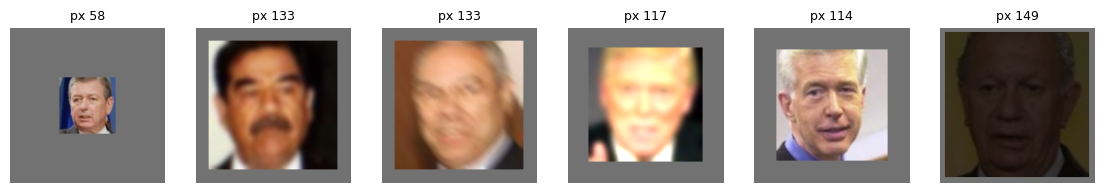

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(SEED)
HEADS = ["face_size", "sharpness", "brightness"]
LABEL_COLS = ["y_size", "y_sharp", "y_bright"]
PAD_VALUE = 114


def to_canvas(img_bgr):
    h, w = img_bgr.shape[:2]
    if max(h, w) > CANVAS:                                   # only ever shrink, never enlarge
        s = CANVAS / max(h, w)
        img_bgr = cv2.resize(img_bgr, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
        h, w = img_bgr.shape[:2]
    canvas = np.full((CANVAS, CANVAS, 3), PAD_VALUE, np.uint8)
    y0, x0 = (CANVAS - h) // 2, (CANVAS - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = img_bgr
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


def make_xy(images, df):
    X = np.stack([to_canvas(im) for im in images]).astype(np.uint8)
    Y = df[LABEL_COLS].values.astype("float32")
    return X, Y


X_train, Y_train = make_xy(train_imgs, train_df)
X_val,   Y_val   = make_xy(val_imgs,   val_df)
X_test,  Y_test  = make_xy(test_imgs,  test_df)
print("Arrays:", X_train.shape, X_val.shape, X_test.shape)

# What the network actually sees
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
for ax, i in zip(axes, rng.choice(len(X_train), 6, replace=False)):
    ax.imshow(X_train[i]); ax.axis("off")
    ax.set_title("px %d" % train_df.face_px.iloc[i], fontsize=9)
plt.show()

In [14]:
def build_cnn(pretrained):
    weights = "imagenet" if pretrained else None
    try:
        backbone = tf.keras.applications.MobileNetV3Small(
            input_shape=(CANVAS, CANVAS, 3), include_top=False, weights=weights, include_preprocessing=True)
        loaded = pretrained
    except Exception as e:
        print("WARNING: could not load ImageNet weights, so the network will be trained from scratch "
              "(results will be much worse):", e)
        backbone = tf.keras.applications.MobileNetV3Small(
            input_shape=(CANVAS, CANVAS, 3), include_top=False, weights=None, include_preprocessing=True)
        loaded = False

    if not loaded:
        # Default BatchNorm momentum (0.999) updates the running statistics too slowly for a short run,
        # which makes predictions differ from training behaviour. Use a faster update.
        for l in backbone.layers:
            if isinstance(l, layers.BatchNormalization):
                l.momentum = 0.9

    inputs = layers.Input(shape=(CANVAS, CANVAS, 3))            # pixel values 0-255
    x = layers.RandomFlip("horizontal")(inputs)
    x = backbone(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(3, activation="sigmoid", name="flags")(x)
    model = Model(inputs, outputs)

    def set_backbone_trainable(flag):
        backbone.trainable = flag
        if loaded:
            # Keep the pretrained BatchNorm statistics fixed (BatchNorm in inference mode).
            # Setting backbone.trainable = True would otherwise switch them back to training mode.
            for l in backbone.layers:
                if isinstance(l, layers.BatchNormalization):
                    l.trainable = False

    set_backbone_trainable(not loaded)
    return model, set_backbone_trainable, loaded


def compile_cnn(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.BinaryAccuracy(name="acc")])


cnn, set_backbone_trainable, pretrained_loaded = build_cnn(PRETRAINED)
cnn.summary()

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 5, 5, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flags (Dense)                   │ (None, 3)              │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 940,851 (3.59 MB)

 Trainable params: 1,731 (6.76 KB)

 Non-trainable params: 939,120 (3.58 MB)

Phase 1: train the new output layer only
Epoch 1/4
145/145 - 32s - 219ms/step - acc: 0.8278 - loss: 0.3979 - val_acc: 0.9300 - val_loss: 0.2329
Epoch 2/4
145/145 - 2s - 13ms/step - acc: 0.9286 - loss: 0.2154 - val_acc: 0.9495 - val_loss: 0.1707
Epoch 3/4
145/145 - 2s - 12ms/step - acc: 0.9428 - loss: 0.1739 - val_acc: 0.9538 - val_loss: 0.1441
Epoch 4/4
145/145 - 2s - 11ms/step - acc: 0.9483 - loss: 0.1534 - val_acc: 0.9609 - val_loss: 0.1281
Phase 2: fine-tune the whole network
Epoch 1/15
145/145 - 72s - 497ms/step - acc: 0.9818 - loss: 0.0497 - val_acc: 0.9893 - val_loss: 0.0347
Epoch 2/15
145/145 - 4s - 27ms/step - acc: 0.9936 - loss: 0.0175 - val_acc: 0.9925 - val_loss: 0.0231
Epoch 3/15
145/145 - 4s - 26ms/step - acc: 0.9958 - loss: 0.0114 - val_acc: 0.9831 - val_loss: 0.0508
Epoch 4/15
145/145 - 4s - 28ms/step - acc: 0.9962 - loss: 0.0096 - val_acc: 0.9922 - val_loss: 0.0263
Epoch 5/15
145/145 - 4s - 27ms/step - acc: 0.9978 - loss: 0.0061 - val_acc: 0.9938 - val_loss: 0.0198
Epoc

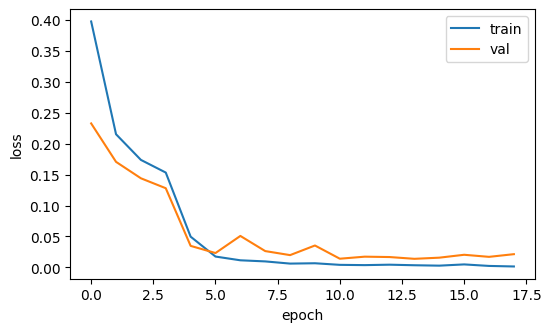

In [15]:
histories = []

if pretrained_loaded and EPOCHS_HEAD > 0:
    print("Phase 1: train the new output layer only")
    compile_cnn(cnn, 1e-3)
    histories.append(cnn.fit(X_train, Y_train, validation_data=(X_val, Y_val),
                             epochs=EPOCHS_HEAD, batch_size=BATCH_SIZE, verbose=2))

print("Phase 2: fine-tune the whole network")
set_backbone_trainable(True)
compile_cnn(cnn, 1e-4 if pretrained_loaded else 1e-3)
histories.append(cnn.fit(
    X_train, Y_train, validation_data=(X_val, Y_val),
    epochs=EPOCHS_FINETUNE, batch_size=BATCH_SIZE, verbose=2,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)]))

train_loss = sum([h.history["loss"] for h in histories], [])
val_loss = sum([h.history["val_loss"] for h in histories], [])
plt.figure(figsize=(6, 3.5))
plt.plot(train_loss, label="train"); plt.plot(val_loss, label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

## 8. Method B: results on the test split

In [17]:
def cnn_probs(images, batch_size=128):
    X = np.stack([to_canvas(im) for im in images]).astype(np.uint8) if isinstance(images, list) else images
    return cnn.predict(X, batch_size=batch_size, verbose=0)


def probs_to_pred(probs, index=None):
    pred = pd.DataFrame(probs >= 0.5, columns=HEADS, index=index)
    pred["is_acceptable"] = pred[HEADS].all(axis=1)
    return pred


test_probs = cnn_probs(X_test)
pred_B = probs_to_pred(test_probs, index=test_df.index)

print("=== Method B (MobileNetV3-Small) ===")
results_B = evaluate_pred(test_df, pred_B, show_confusion=True)
print()
print(results_B.round(3).to_string())

=== Method B (MobileNetV3-Small) ===

face_size: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[413   3]
 [  1 609]]

sharpness: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[419   1]
 [  3 603]]

brightness: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[397   1]
 [  0 628]]

is_acceptable: confusion matrix (rows = truth [bad, good], cols = predicted [bad, good])
[[802   4]
 [  2 218]]

               precision  recall     f1  n_true     n
check                                                
face_size          0.995   0.998  0.997     610  1026
sharpness          0.998   0.995  0.997     606  1026
brightness         0.998   1.000  0.999     628  1026
is_acceptable      0.982   0.991  0.986     220  1026


## 9. Compare the two methods

Both are scored on the identical test split. Look at **precision** and **recall** for `is_acceptable`, not just F1: a method that accepts bad faces and a method that rejects good faces fail in different ways.

                                      precision  recall     f1
check         method                                          
brightness    A: OpenCV + thresholds      1.000   1.000  1.000
              B: MobileNetV3-Small        0.998   1.000  0.999
face_size     A: OpenCV + thresholds      1.000   1.000  1.000
              B: MobileNetV3-Small        0.995   0.998  0.997
is_acceptable A: OpenCV + thresholds      0.977   0.973  0.975
              B: MobileNetV3-Small        0.982   0.991  0.986
sharpness     A: OpenCV + thresholds      0.856   0.974  0.911
              B: MobileNetV3-Small        0.998   0.995  0.997

ROC-AUC of quality_score vs is_acceptable
  A: OpenCV + thresholds : 0.998
  B: MobileNetV3-Small   : 0.9998


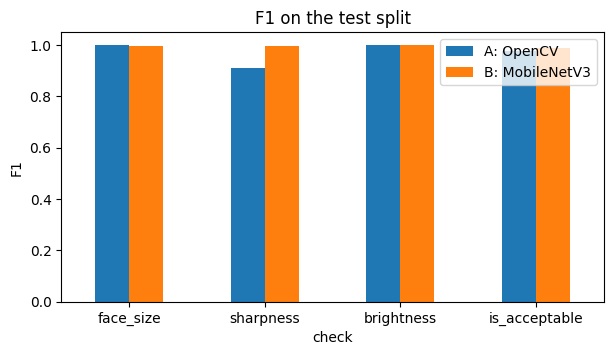

In [18]:
pred_A = predict_df(test_df, CALIBRATED_THRESHOLDS)

comparison = pd.concat({"A: OpenCV + thresholds": results_A[["precision", "recall", "f1"]],
                        "B: MobileNetV3-Small": results_B[["precision", "recall", "f1"]]}, names=["method"])
comparison = comparison.reorder_levels(["check", "method"]).sort_index(level="check", sort_remaining=False)
print(comparison.round(3).to_string())

# Quality-score ranking quality (ROC-AUC against is_acceptable)
score_A = np.array([assess_face_quality(im)["quality_score"] for im in test_imgs])
score_B = test_probs.min(axis=1)
print("\nROC-AUC of quality_score vs is_acceptable")
print("  A: OpenCV + thresholds :", round(roc_auc_score(test_df["y_ok"], score_A), 4))
print("  B: MobileNetV3-Small   :", round(roc_auc_score(test_df["y_ok"], score_B), 4))

# F1 per check, side by side
f1_table = pd.DataFrame({"A: OpenCV": results_A["f1"], "B: MobileNetV3": results_B["f1"]})
f1_table.plot(kind="bar", figsize=(7, 3.5), ylim=(0, 1.05)); plt.ylabel("F1"); plt.xticks(rotation=0)
plt.title("F1 on the test split"); plt.show()

## 10. Error analysis

Look at what each method gets wrong before you trust it.

A: OpenCV - false accepts (bad images that were accepted): 5


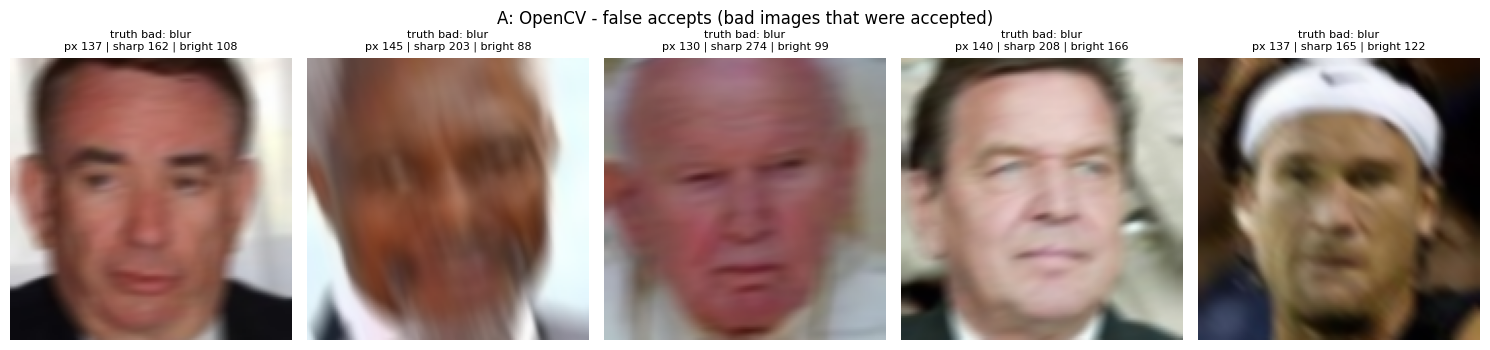

A: OpenCV - false rejects (fine images that were rejected): 6


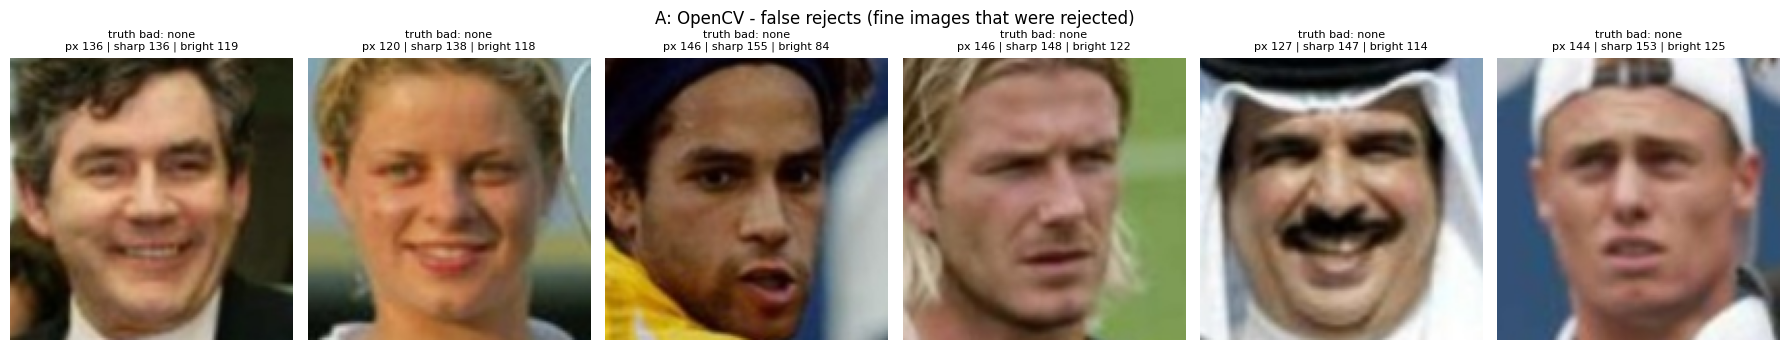

B: MobileNetV3 - false accepts (bad images that were accepted): 4


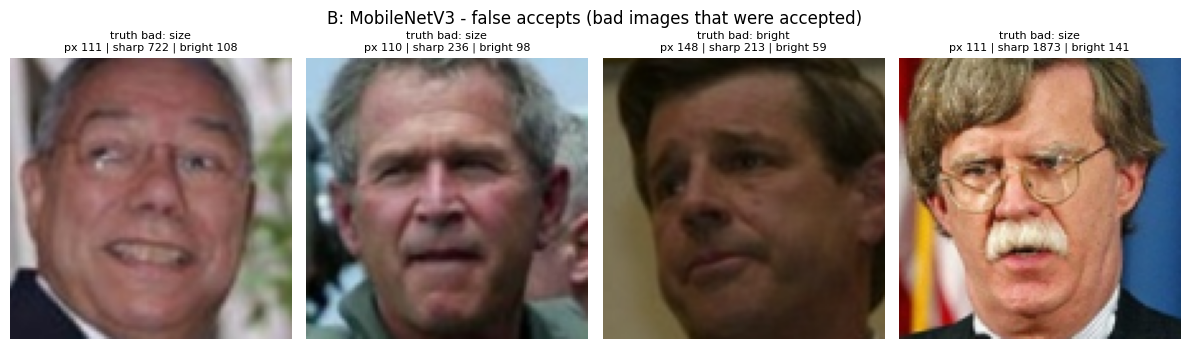

B: MobileNetV3 - false rejects (fine images that were rejected): 2


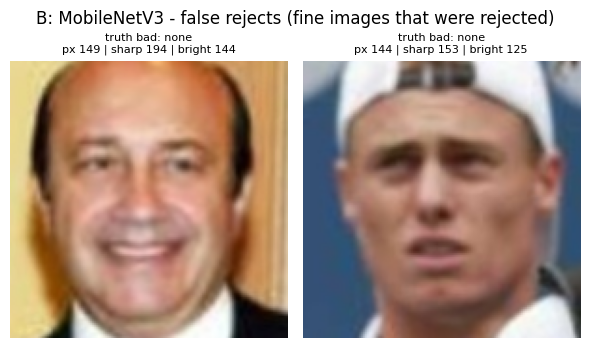

In [19]:
def show_errors(pred_ok, title, kind, n=6):
    truth = test_df["y_ok"].values
    idx_err = np.where((pred_ok & ~truth) if kind == "fp" else (~pred_ok & truth))[0]
    print(f"{title}: {len(idx_err)}")
    if len(idx_err) == 0:
        return
    pick = rng.choice(idx_err, min(n, len(idx_err)), replace=False)
    fig, axes = plt.subplots(1, len(pick), figsize=(3 * len(pick), 3.6), squeeze=False)
    for ax, i in zip(axes[0], pick):
        r = test_df.iloc[i]
        ax.imshow(cv2.cvtColor(test_imgs[i], cv2.COLOR_BGR2RGB)); ax.axis("off")
        truth_bad = [nm for nm, k in [("size", "y_size"), ("blur", "y_sharp"), ("bright", "y_bright")] if not r[k]]
        ax.set_title(f"truth bad: {','.join(truth_bad) or 'none'}\n"
                     f"px {r.face_px} | sharp {r.sharpness:.0f} | bright {r.brightness:.0f}", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()


for label, pred in [("A: OpenCV", pred_A), ("B: MobileNetV3", pred_B)]:
    ok = pred["is_acceptable"].values
    show_errors(ok, f"{label} - false accepts (bad images that were accepted)", "fp")
    show_errors(ok, f"{label} - false rejects (fine images that were rejected)", "fn")

## 11. Evaluate on real images you label yourself (recommended for the final report)

Synthetic labels are easy. A small set of **real** photos labeled by humans is a much stronger test, and it shows whether the CNN learned real quality problems or only the degradations generated here. Collect roughly 100–200 cropped faces with a mix of good and bad quality, and make a CSV named `labels.csv` with these columns (1 = acceptable, 0 = not acceptable):

```text
filename,face_size,sharpness,brightness
img001.jpg,1,1,1
img002.jpg,1,0,1
```

Label each attribute independently, using written rules your team agrees on. Set `RUN_REAL_EVAL = True` and upload the images together with the CSV. If the scores are much lower than on the synthetic data, re-calibrate (method A) or fine-tune (method B) on part of your real set and test on the rest.

In [20]:
RUN_REAL_EVAL = False

if RUN_REAL_EVAL:
    if IN_COLAB:
        from google.colab import files
        uploaded = files.upload()          # select the images AND labels.csv together
    labels = pd.read_csv("labels.csv")
    real_imgs = [read_image(f) for f in labels["filename"]]
    real_df = pd.DataFrame([{
        **measure_face_quality(im),
        "y_size": bool(r.face_size), "y_sharp": bool(r.sharpness), "y_bright": bool(r.brightness),
        "y_ok": bool(r.face_size and r.sharpness and r.brightness)}
        for im, r in zip(real_imgs, labels.itertuples())])
    print(f"{len(real_df)} real images")
    print("\n=== A: OpenCV + thresholds ===")
    print(evaluate(real_df, THRESHOLDS, show_confusion=True).round(3).to_string())
    print("\n=== B: MobileNetV3-Small ===")
    print(evaluate_pred(real_df, probs_to_pred(cnn_probs(real_imgs), index=real_df.index),
                        show_confusion=True).round(3).to_string())
else:
    print("Skipped (set RUN_REAL_EVAL = True to use your own labeled images).")

Skipped (set RUN_REAL_EVAL = True to use your own labeled images).


## 12. Try it on a single image

Both methods return exactly the fields requested in the spec.

Method A: {
  "quality_score": 0.2637,
  "is_acceptable": false,
  "face_size": false,
  "sharpness": true,
  "brightness": true,
  "metrics": {
    "face_px": 100,
    "sharpness": 908.847,
    "brightness": 129.838
  }
}
Method B: {
  "quality_score": 0.0,
  "is_acceptable": false,
  "face_size": false,
  "sharpness": true,
  "brightness": true,
  "probabilities": {
    "face_size": 0.0,
    "sharpness": 1.0,
    "brightness": 1.0
  }
}


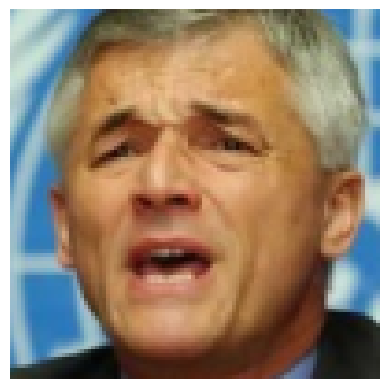

Saving 1793526789549_252890048193787684_1458033214560754077_cb0808509de17ca595111e7fbb4cd297.jpg to 1793526789549_252890048193787684_1458033214560754077_cb0808509de17ca595111e7fbb4cd297.jpg
1793526789549_252890048193787684_1458033214560754077_cb0808509de17ca595111e7fbb4cd297.jpg
A: {"quality_score": 0.9722, "is_acceptable": true, "face_size": true, "sharpness": true, "brightness": true, "metrics": {"face_px": 960, "sharpness": 1069.894, "brightness": 110.157}}
B: {"quality_score": 0.9998, "is_acceptable": true, "face_size": true, "sharpness": true, "brightness": true, "probabilities": {"face_size": 1.0, "sharpness": 1.0, "brightness": 0.9998}}


In [21]:
def assess_face_quality_cnn(img):
    # Method B. Same output fields as method A.
    probs = cnn_probs([read_image(img)])[0]
    flags = [bool(p >= 0.5) for p in probs]
    return {
        "quality_score": round(float(probs.min()), 4),
        "is_acceptable": bool(all(flags)),
        "face_size": flags[0],
        "sharpness": flags[1],
        "brightness": flags[2],
        "probabilities": {h: round(float(p), 4) for h, p in zip(HEADS, probs)},
    }


example = test_imgs[0]
print("Method A:", json.dumps(assess_face_quality(example), indent=2))
print("Method B:", json.dumps(assess_face_quality_cnn(example), indent=2))
plt.imshow(cv2.cvtColor(example, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

# Your own cropped face image (Colab only)
if IN_COLAB:
    from google.colab import files
    up = files.upload()
    for name in up:
        print(name)
        print("A:", json.dumps(assess_face_quality(name)))
        print("B:", json.dumps(assess_face_quality_cnn(name)))

## 13. Save the thresholds and the trained model

In [22]:
with open("fqa_thresholds.json", "w") as f:
    json.dump(CALIBRATED_THRESHOLDS, f, indent=2)
cnn.save("fqa_mobilenetv3_small.keras")
print(open("fqa_thresholds.json").read())
print("Saved fqa_thresholds.json and fqa_mobilenetv3_small.keras")

if IN_COLAB:
    from google.colab import files
    files.download("fqa_thresholds.json")
    files.download("fqa_mobilenetv3_small.keras")

{
  "min_face_px": 112,
  "min_sharpness": 157.12,
  "min_brightness": 67.5,
  "max_brightness": 197.5
}
Saved fqa_thresholds.json and fqa_mobilenetv3_small.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes and limitations

- **Synthetic labels:** the main results measure agreement with known, programmatically applied degradations. Report them as such, and report section 11 results separately if you have them.
- **The CNN may only learn these degradations.** It is trained on exactly the blur, darkening and shrinking generated here. Real-world problems (motion in a phone photo, compression, noise, backlighting) may look different, so test on real images before claiming it generalises.
- **Clean-set selection:** the base images were filtered with a different sharpness measure (Tenengrad) so method A's metric doesn't choose its own "good" examples. The filter still keeps natural variety, so some borderline cases remain.
- **Face size** is the crop's shorter side in pixels. In your pipeline, the face detector's bounding box already gives this directly, so a CNN is not needed for that check. If crops are always resized to a fixed size before this stage, measure the size *before* resizing.
- **Sharpness** depends on image content (glasses, facial hair, texture) as well as focus, so a single threshold cannot be perfect. Compression artifacts and noise can inflate it.
- **Brightness** uses the mean gray level. It can't tell a naturally dark-skinned face in good light from an under-exposed one; check this on your own data and consider per-group evaluation.
- **Not covered:** pose, occlusion, expression, and whether the image is actually a face.
- The `quality_score` in both methods is a convenient summary (weakest link), not a calibrated probability of being acceptable.